# Notebook 1 — Análise Exploratória de Dados (AED)

**TCC — Desenvolvimento de modelo preditivo interpretável de machine learning para identificação de alunos em risco de evasão no ensino superior**
Curso de Sistemas de Informação — UEMG

---

## Objetivo

Este notebook corresponde à **Fase 2 do CRISP-DM — Entendimento dos Dados** (*Data Understanding*).
A meta aqui **não é modelar**, e sim conhecer o material de trabalho: descobrir o que cada variável
representa, quão íntegros são os registros, como a variável-alvo se distribui e quais atributos
apresentam, à primeira vista, maior associação com a evasão.

As decisões de pré-processamento (codificação, escalonamento, balanceamento) ficam para o
Notebook 2. Aqui apenas **observamos e documentamos**.

## Sobre o conjunto de dados

| Item | Descrição |
|---|---|
| **Nome** | *Predict Students' Dropout and Academic Success* |
| **Origem** | Realinho, V.; Machado, J.; Baptista, L.; Martins, M. V. (2022) — UCI ML Repository, id **697** |
| **Instituição** | Instituto Politécnico de Portalegre (Portugal) |
| **Registros** | 4.424 estudantes de graduação |
| **Atributos** | 36 variáveis independentes |
| **Variável-alvo** | `target` — três classes: `Dropout`, `Enrolled`, `Graduate` |

As variáveis cobrem quatro dimensões: **demográfica** (idade, gênero, estado civil, nacionalidade),
**socioeconômica** (escolaridade e ocupação dos pais, bolsa, inadimplência), **acadêmica**
(nota de admissão, disciplinas matriculadas/aprovadas e médias do 1º e 2º semestres) e
**macroeconômica** (desemprego, inflação, PIB no período).

Neste trabalho os dados foram previamente carregados em um **banco MySQL local**, modelados em
esquema dimensional, com uma *view* flat (`vw_dataset_ml`) preparada para o pipeline de ML.
O carregamento abaixo tenta o MySQL primeiro e, se ele não estiver acessível, recorre
automaticamente ao repositório UCI — garantindo que o notebook seja **reprodutível por qualquer
membro da banca**, mesmo sem acesso ao banco local.

## 1. Configuração do ambiente

In [1]:
# --- Bibliotecas padrão do pipeline -----------------------------------------
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Semente global: garante que qualquer sorteio (amostragens, splits) seja reprodutível.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Diretórios do projeto ---------------------------------------------------
DIR_DADOS = "dados"
DIR_FIGURAS = "figuras"
os.makedirs(DIR_DADOS, exist_ok=True)
os.makedirs(DIR_FIGURAS, exist_ok=True)

# --- Módulo próprio de carga (src/data_loader.py) ---------------------------
sys.path.insert(0, "src")
from data_loader import carregar_dados, rotulo, tipologia   # noqa: E402

# --- Padrão visual dos gráficos ---------------------------------------------
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# Paleta fixa por classe — a mesma será usada em todos os notebooks,
# para que a banca leia os gráficos sempre com o mesmo código de cores.
CORES_CLASSE = {"Dropout": "#c0392b", "Enrolled": "#e67e22", "Graduate": "#27ae60"}


def salvar_fig(nome_arquivo):
    """Salva a figura corrente em figuras/ (PNG, pronta para a monografia)."""
    caminho = os.path.join(DIR_FIGURAS, nome_arquivo)
    plt.savefig(caminho)
    print(f"[figura salva] {caminho}")


print("Versões em uso")
print(f"  pandas       : {pd.__version__}")
print(f"  numpy        : {np.__version__}")
print(f"  seaborn      : {sns.__version__}")
print(f"  Python       : {sys.version.split()[0]}")

Versões em uso
  pandas       : 3.0.5
  numpy        : 2.5.2
  seaborn      : 0.13.2
  Python       : 3.14.4


## 2. Carga dos dados

A função `carregar_dados()` (definida em [`src/data_loader.py`](src/data_loader.py)) executa:

1. **Fonte primária — MySQL:** lê host, usuário, senha, banco e nome da *view* das variáveis de
   ambiente definidas no arquivo `.env` (carregado com `python-dotenv`).
   **Nenhuma credencial aparece no notebook** — requisito de segurança e boa prática de
   versionamento (o `.env` está no `.gitignore`).
2. **Fallback — UCI:** se a conexão falhar por qualquer motivo, baixa o dataset original
   via `ucimlrepo` (id = 697).
3. **Padronização:** converte todos os nomes de coluna para `snake_case` sem acentos e descarta
   colunas de identificação (chaves substitutas do modelo dimensional), que não são preditores.

Assim, o restante do pipeline funciona **independentemente da fonte**.

In [2]:
df, origem = carregar_dados()
print(f"\nOrigem efetiva dos dados: {origem}")

[OK] Dados carregados do MySQL: tcc.data
[CORREÇÃO] curricular_units_1st_sem_grade: 1672 de 4424 valores (37.8%) reconstruídos (separador de milhar indevido).
[CORREÇÃO] curricular_units_2nd_sem_grade: 1558 de 4424 valores (35.2%) reconstruídos (separador de milhar indevido).
[INFO] Dimensões: 4424 linhas x 37 colunas

Origem efetiva dos dados: MySQL


## 3. Primeiro contato com os dados

### 3.1 Dimensões, tipos e primeiras linhas

In [3]:
print(f"Linhas   : {df.shape[0]:,}".replace(",", "."))
print(f"Colunas  : {df.shape[1]} ({df.shape[1] - 1} preditoras + 1 alvo)")
print(f"Memória  : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Linhas   : 4.424
Colunas  : 37 (36 preditoras + 1 alvo)
Memória  : 1.45 MB


In [4]:
# Primeiras linhas — visão concreta do formato dos registros
df.head()

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nacionality,mothers_qualification,fathers_qualification,...,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [5]:
# Tipos de dados e contagem de não-nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   marital_status                                4424 non-null   int64  
 1   application_mode                              4424 non-null   int64  
 2   application_order                             4424 non-null   int64  
 3   course                                        4424 non-null   int64  
 4   daytime_evening_attendance                    4424 non-null   int64  
 5   previous_qualification                        4424 non-null   int64  
 6   previous_qualification_grade                  4424 non-null   float64
 7   nacionality                                   4424 non-null   int64  
 8   mothers_qualification                         4424 non-null   int64  
 9   fathers_qualification                         4424 non-null   int64  
 10 

### 3.2 Tipologia das variáveis — um cuidado essencial

Um erro frequente neste dataset é olhar o `dtype` e concluir que "está tudo numérico, logo é tudo
contínuo". **Não é.** Boa parte dos inteiros são **códigos de categorias** definidos pela instituição
portuguesa. Por exemplo, `course` assume valores como 33, 171, 8014 — que identificam
*Serviço Social*, *Design*, *Enfermagem* etc. Tratar isso como grandeza contínua faria o modelo
supor que "curso 8014 > curso 171", uma ordenação que **não existe na realidade**.

Por isso o módulo `data_loader` classifica explicitamente as colunas em três grupos:

* **Contínuas / ordinais** — notas, idade, contagens de disciplinas, indicadores macroeconômicos;
* **Binárias** — indicadores 0/1 (bolsista, inadimplente, deslocado, ...);
* **Nominais codificadas** — códigos sem ordem natural (curso, modalidade de ingresso, ocupação dos pais, ...).

Essa separação será reaproveitada no Notebook 2 para decidir **o que escalonar** e **o que codificar**.

In [6]:
tipos = tipologia(df)

for nome, colunas in tipos.items():
    print(f"\n{nome.upper()} ({len(colunas)} variáveis)")
    for c in colunas:
        print(f"   - {c:<48} | {rotulo(c)}")

total_classificadas = sum(len(v) for v in tipos.values())
nao_classificadas = [c for c in df.columns if c != "target" and
                     c not in tipos["continuas"] + tipos["binarias"] + tipos["nominais"]]
print(f"\nTotal classificado: {total_classificadas} | Alvo: 1 | Não classificadas: {len(nao_classificadas)}")
if nao_classificadas:
    print("Atenção — colunas sem classificação:", nao_classificadas)


CONTINUAS (19 variáveis)
   - previous_qualification_grade                     | Nota da formação anterior
   - admission_grade                                  | Nota de admissão
   - age_at_enrollment                                | Idade no ingresso
   - curricular_units_1st_sem_credited                | Disciplinas creditadas (1º sem.)
   - curricular_units_1st_sem_enrolled                | Disciplinas matriculadas (1º sem.)
   - curricular_units_1st_sem_evaluations             | Avaliações realizadas (1º sem.)
   - curricular_units_1st_sem_approved                | Disciplinas aprovadas (1º sem.)
   - curricular_units_1st_sem_grade                   | Média das notas (1º sem.)
   - curricular_units_1st_sem_without_evaluations     | Disciplinas sem avaliação (1º sem.)
   - curricular_units_2nd_sem_credited                | Disciplinas creditadas (2º sem.)
   - curricular_units_2nd_sem_enrolled                | Disciplinas matriculadas (2º sem.)
   - curricular_units_2nd_sem_evalu

## 4. Qualidade dos dados

Antes de qualquer análise estatística é preciso responder: **os dados são confiáveis?**
Verificamos valores ausentes, registros duplicados e colunas constantes (sem variabilidade,
portanto inúteis para o modelo).

In [7]:
# --- Valores ausentes --------------------------------------------------------
nulos = df.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)

if nulos.empty:
    print("Valores ausentes: NENHUM. O dataset está completo em todas as 4.424 observações.")
else:
    print("Valores ausentes por coluna:")
    display(pd.DataFrame({"nulos": nulos, "% do total": (nulos / len(df) * 100).round(2)}))

Valores ausentes: NENHUM. O dataset está completo em todas as 4.424 observações.


In [8]:
# --- Registros duplicados ----------------------------------------------------
n_dup = df.duplicated().sum()
print(f"Registros integralmente duplicados: {n_dup}")

# --- Colunas constantes (variância zero) -------------------------------------
constantes = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(f"Colunas constantes (sem poder preditivo): {constantes if constantes else 'nenhuma'}")

# --- Cardinalidade das nominais ---------------------------------------------
print("\nCardinalidade das variáveis nominais codificadas:")
for c in tipos["nominais"]:
    print(f"   {c:<28} -> {df[c].nunique():>3} categorias distintas")

Registros integralmente duplicados: 0
Colunas constantes (sem poder preditivo): nenhuma

Cardinalidade das variáveis nominais codificadas:
   marital_status               ->   6 categorias distintas
   application_mode             ->  18 categorias distintas
   course                       ->  17 categorias distintas
   previous_qualification       ->  17 categorias distintas
   nacionality                  ->  21 categorias distintas
   mothers_qualification        ->  29 categorias distintas
   fathers_qualification        ->  34 categorias distintas
   mothers_occupation           ->  32 categorias distintas
   fathers_occupation           ->  46 categorias distintas


> ### Conclusão parcial — qualidade
>
> O conjunto **não possui valores ausentes nem duplicatas**, o que é coerente com a descrição de
> Realinho et al. (2022): os autores já haviam realizado um pré-tratamento para remover
> inconsistências e anomalias antes da publicação.
>
> **Implicação prática:** não será necessária nenhuma estratégia de imputação (média, mediana, KNN),
> o que **elimina uma fonte relevante de viés** e simplifica o pipeline. Em compensação, isso também
> significa que o dataset é mais "limpo" do que a realidade de um sistema acadêmico brasileiro —
> ponto a ser registrado nas limitações do trabalho.
>
> A alta cardinalidade de algumas nominais (`course`, `mothers_occupation`, `application_mode`) é o
> principal desafio de codificação a ser tratado no Notebook 2.

### 4.1 Falha de integridade encontrada na carga do MySQL

A inspeção do schema revelou um problema que **não aparece em nenhuma verificação padrão**
(não é nulo, não é duplicata, não é constante): as colunas
`Curricular units 1st sem (grade)` e `Curricular units 2nd sem (grade)` foram gravadas na
tabela `data` como **TEXT**, e parte expressiva dos valores chegou deformada por um erro
clássico de importação de CSV — o ponto decimal foi reinterpretado como **separador de milhar**
pela planilha antes da carga:

| Valor real | Como está gravado no banco |
|---|---|
| `13,42857142857140` | `"13.428.571.428.571.400"` |
| `11,4375` | `"114.375"` |

Se lidas ingenuamente com `float()`, essas notas virariam valores como **114,375 numa escala 0–20** —
contaminando médias, correlações, o `StandardScaler` e, no limite, o modelo inteiro.

**Por que a correção é determinística e não um chute.** A nota é uma média na escala 0–20 e, no
dataset original, *toda* nota diferente de zero está entre **9,80 e 18,875** — sempre com exatamente
dois dígitos na parte inteira (as notas zero foram gravadas como `"0.0"`). Portanto: um valor é
íntegro quando tem no máximo um ponto, no máximo dois dígitos inteiros e cai em [0, 20]; em qualquer
outra forma, basta remover os pontos e recolocar a vírgula após o 2º dígito. A posição é única.

A regra está implementada em `reparar_notas()` no módulo `src/data_loader.py` e é aplicada
automaticamente na carga. A célula abaixo **audita** o resultado contra a fonte oficial.

In [9]:
# --- Auditoria de integridade: banco local x fonte oficial (UCI id=697) ------
# Reexecutável: comprova que a correção reconstrói os valores originais.
COLS_NOTA = ["curricular_units_1st_sem_grade", "curricular_units_2nd_sem_grade"]

print("Notas semestrais após a correção:")
display(df[COLS_NOTA].describe().T.round(4))

try:
    from ucimlrepo import fetch_ucirepo
    from data_loader import _slug

    _ref = fetch_ucirepo(id=697)
    referencia = pd.concat([_ref.data.features, _ref.data.targets], axis=1)
    referencia.columns = [_slug(c) for c in referencia.columns]

    print("\nComparação linha a linha com o UCI (todas as 37 colunas):")
    divergentes = []
    for coluna in referencia.columns:
        if pd.api.types.is_numeric_dtype(referencia[coluna]):
            igual = np.allclose(df[coluna], referencia[coluna], atol=1e-6)
        else:
            igual = df[coluna].astype(str).equals(referencia[coluna].astype(str))
        if not igual:
            divergentes.append(coluna)

    if divergentes:
        print(f"   [ATENÇÃO] {len(divergentes)} coluna(s) divergem: {divergentes}")
    else:
        print(f"   [OK] {len(referencia.columns)}/{len(referencia.columns)} colunas idênticas.")
        print("   A base local, após a correção, reproduz exatamente o dataset publicado.")
except Exception as erro:
    print(f"\n[INFO] Auditoria contra o UCI não executada ({type(erro).__name__}).")
    print("       Requer conexão com a internet. A correção independe dela.")

Notas semestrais após a correção:


,count,mean,std,min,25%,50%,75%,max
curricular_units_1st_sem_grade,4424.0,10.6408,4.8437,0.0,11.00,12.2857,13.4000,18.8750
curricular_units_2nd_sem_grade,4424.0,10.2302,5.2108,0.0,10.75,12.2000,13.3333,18.5714



Comparação linha a linha com o UCI (todas as 37 colunas):
   [OK] 37/37 colunas idênticas.
   A base local, após a correção, reproduz exatamente o dataset publicado.


> ### Conclusão parcial — integridade da origem
>
> A base local reproduz **exatamente** o dataset publicado por Realinho et al. (2022) nas 37 colunas,
> na mesma ordem de registros, depois de reconstruídos **3.230 valores de nota** (1.672 no 1º semestre
> e 1.558 no 2º) — cerca de 36% da amostra em cada coluna. A verificação acima é reexecutável e serve
> como evidência de procedência dos dados na defesa.
>
> **Duas lições metodológicas para o TCC:**
>
> 1. *Ausência de nulos não é sinônimo de qualidade.* O erro passaria despercebido por
>    `isnull()`, `duplicated()` e `describe()` — só apareceu ao confrontar o **tipo declarado no
>    schema** (`TEXT` onde deveria haver `DOUBLE`) com o **domínio esperado** da variável (0–20).
>    Validar faixa e tipo é parte do entendimento dos dados, não um detalhe de engenharia.
> 2. *A correção precisa ser justificável, não conveniente.* Ela só é defensável porque o domínio
>    da variável torna a posição do separador decimal única — e porque foi auditada contra a fonte
>    original. Registrar esse raciocínio é o que separa tratamento de dado de manipulação de dado.
>
> **Recomendação para o banco:** alterar as duas colunas para `DOUBLE` e recarregá-las com o
> separador decimal correto, evitando que qualquer outra consulta ao banco (fora deste pipeline)
> leia os valores deformados.

## 5. Estatísticas descritivas

Analisamos apenas as variáveis **contínuas/ordinais**: calcular média de um código de curso não teria
sentido interpretativo.

In [10]:
desc = df[tipos["continuas"]].describe().T
desc["amplitude"] = desc["max"] - desc["min"]
desc["cv_%"] = (desc["std"] / desc["mean"].replace(0, np.nan) * 100).round(1)
desc.index = [rotulo(i) for i in desc.index]
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,amplitude,cv_%
Nota da formação anterior,4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00,95.00,9.9
Nota de admissão,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00,95.00,11.4
Idade no ingresso,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00,53.00,32.6
Disciplinas creditadas (1º sem.),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00,20.00,332.5
Disciplinas matriculadas (1º sem.),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00,26.00,39.6
Avaliações realizadas (1º sem.),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00,45.00,50.4
Disciplinas aprovadas (1º sem.),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00,26.00,65.7
Média das notas (1º sem.),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88,18.88,45.5
Disciplinas sem avaliação (1º sem.),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00,12.00,501.9
Disciplinas creditadas (2º sem.),4424.0,0.54,1.92,0.00,0.00,0.00,0.00,19.00,19.00,354.1


In [11]:
# Proporção de 1 nas variáveis binárias — leitura direta do perfil da amostra
prop_bin = (df[tipos["binarias"]].mean() * 100).sort_values(ascending=False)
prop_bin.index = [rotulo(i) for i in prop_bin.index]
print("Percentual de alunos com valor 1 em cada variável binária:\n")
print(prop_bin.round(1).to_string())

Percentual de alunos com valor 1 em cada variável binária:

Turno (diurno/noturno)                 89.1
Mensalidades em dia                    88.1
Deslocado da cidade de origem          54.8
Gênero                                 35.2
Bolsista                               24.8
Inadimplente                           11.4
Estudante internacional                 2.5
Necessidades educacionais especiais     1.2


> ### Conclusão parcial — descritivas
>
> Pontos que merecem destaque para a monografia:
>
> * **Idade no ingresso** tem média em torno de 23 anos, mas o máximo chega a 70 — a distribuição é
>   fortemente assimétrica à direita, típica de instituições que recebem estudantes não tradicionais.
> * As variáveis de **disciplinas aprovadas** e **média das notas** apresentam mínimo igual a zero.
>   Isso **não é um erro**: representa alunos que não obtiveram nenhuma aprovação no semestre —
>   exatamente o perfil que esperamos ver associado à evasão.
> * As variáveis **macroeconômicas** (desemprego, inflação, PIB) têm amplitude pequena, pois refletem
>   o contexto do ano de ingresso; sua variabilidade é limitada e sua contribuição preditiva
>   tende a ser modesta.
> * A quase totalidade dos alunos está com **mensalidades em dia**, o que torna a inadimplência uma
>   variável rara — mas potencialmente muito informativa justamente por isso.

## 6. Distribuição da variável-alvo

Esta é a análise mais determinante do notebook: o **grau de desbalanceamento** entre as classes
define a estratégia de balanceamento (SMOTE) e, principalmente, **as métricas de avaliação**.
Com classes desbalanceadas, acurácia é uma métrica enganosa — motivo pelo qual este trabalho
prioriza **F1-score e recall da classe `Dropout`**.

In [12]:
contagem = df["target"].value_counts()
percentual = df["target"].value_counts(normalize=True) * 100

tabela_target = pd.DataFrame({
    "Frequência": contagem,
    "Percentual (%)": percentual.round(2),
})
tabela_target.index.name = "Situação"
display(tabela_target)

print(f"\nRazão de desbalanceamento (maior classe / menor classe): "
      f"{contagem.max() / contagem.min():.2f} : 1")

,Frequência,Percentual (%)
Situação,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95



Razão de desbalanceamento (maior classe / menor classe): 2.78 : 1


[figura salva] figuras\01_distribuicao_target.png


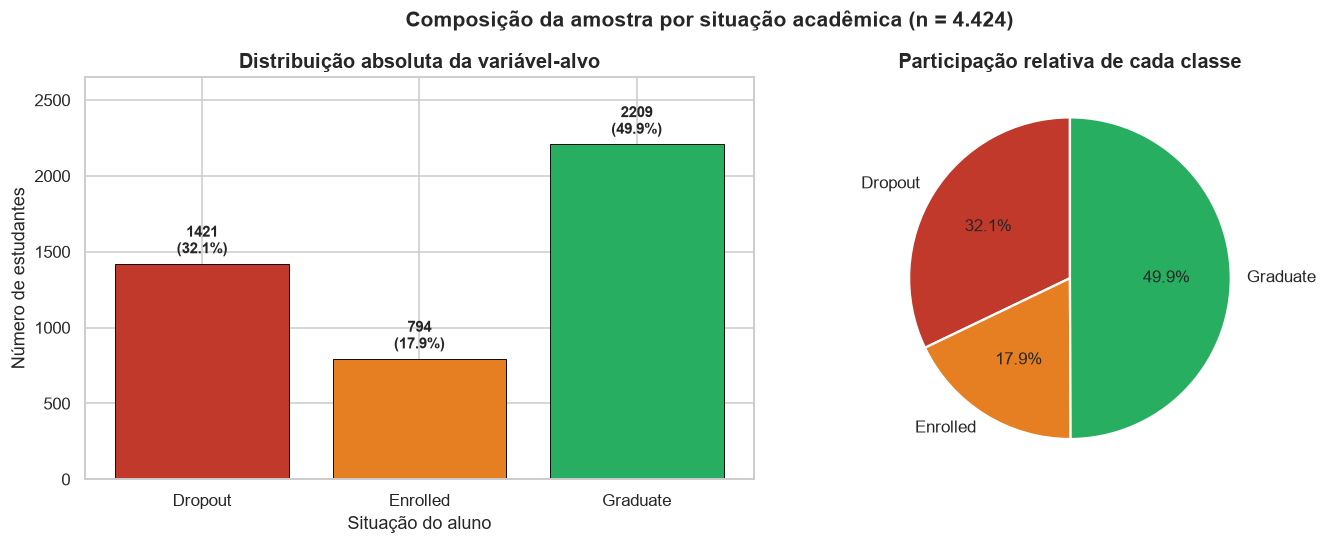

In [13]:
ordem = ["Dropout", "Enrolled", "Graduate"]
ordem = [c for c in ordem if c in contagem.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Gráfico de barras -------------------------------------------------------
valores = [contagem[c] for c in ordem]
barras = axes[0].bar(ordem, valores, color=[CORES_CLASSE[c] for c in ordem],
                     edgecolor="black", linewidth=0.6)
for barra, valor in zip(barras, valores):
    axes[0].text(barra.get_x() + barra.get_width() / 2, valor + 40,
                 f"{valor}\n({valor / len(df) * 100:.1f}%)",
                 ha="center", va="bottom", fontweight="bold", fontsize=10)
axes[0].set_title("Distribuição absoluta da variável-alvo")
axes[0].set_xlabel("Situação do aluno")
axes[0].set_ylabel("Número de estudantes")
axes[0].set_ylim(0, max(valores) * 1.20)

# --- Gráfico de pizza --------------------------------------------------------
axes[1].pie(valores, labels=ordem, autopct="%1.1f%%", startangle=90,
            colors=[CORES_CLASSE[c] for c in ordem],
            wedgeprops={"edgecolor": "white", "linewidth": 1.5},
            textprops={"fontsize": 11})
axes[1].set_title("Participação relativa de cada classe")

plt.suptitle("Composição da amostra por situação acadêmica (n = 4.424)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
salvar_fig("01_distribuicao_target.png")
plt.show()

> ### Conclusão parcial — variável-alvo
>
> A amostra é **desbalanceada, porém não de forma extrema**: a razão entre a maior e a menor classe
> fica em torno de **2,8 : 1**. `Graduate` é a classe majoritária (~50%), `Dropout` responde por
> cerca de **32%** e `Enrolled` por apenas **18%**.
>
> **Três consequências diretas para o projeto:**
>
> 1. **Acurácia é inadequada como métrica principal.** Um classificador ingênuo que respondesse
>    sempre "Graduate" já alcançaria ~50% de acurácia sem identificar um único evadido.
>    Por isso a avaliação será conduzida por **F1-score e recall da classe `Dropout`**.
> 2. **O balanceamento por SMOTE se justifica**, e será aplicado **exclusivamente sobre o conjunto
>    de treino** (Notebook 2). Aplicá-lo antes da divisão treino/teste geraria *data leakage*:
>    exemplos sintéticos interpolados a partir de registros de teste contaminariam a avaliação,
>    produzindo métricas otimistas e irreais.
> 3. **A classe `Enrolled` é ambígua.** Ela agrupa alunos ainda matriculados ao fim do período de
>    observação — cujo desfecho é *desconhecido*. Alguns se formarão, outros evadirão. Manter essa
>    classe insere ruído no aprendizado; a literatura da área majoritariamente a remove, reduzindo
>    o problema a uma classificação binária `Dropout` × `Graduate`. Essa decisão será formalizada
>    e justificada no Notebook 2.

## 7. Distribuição das variáveis numéricas

Histogramas das variáveis contínuas: revelam assimetrias, concentrações em zero e presença de
valores extremos — informações que orientam a necessidade (ou não) de transformações.

[figura salva] figuras\02_histogramas_continuas.png


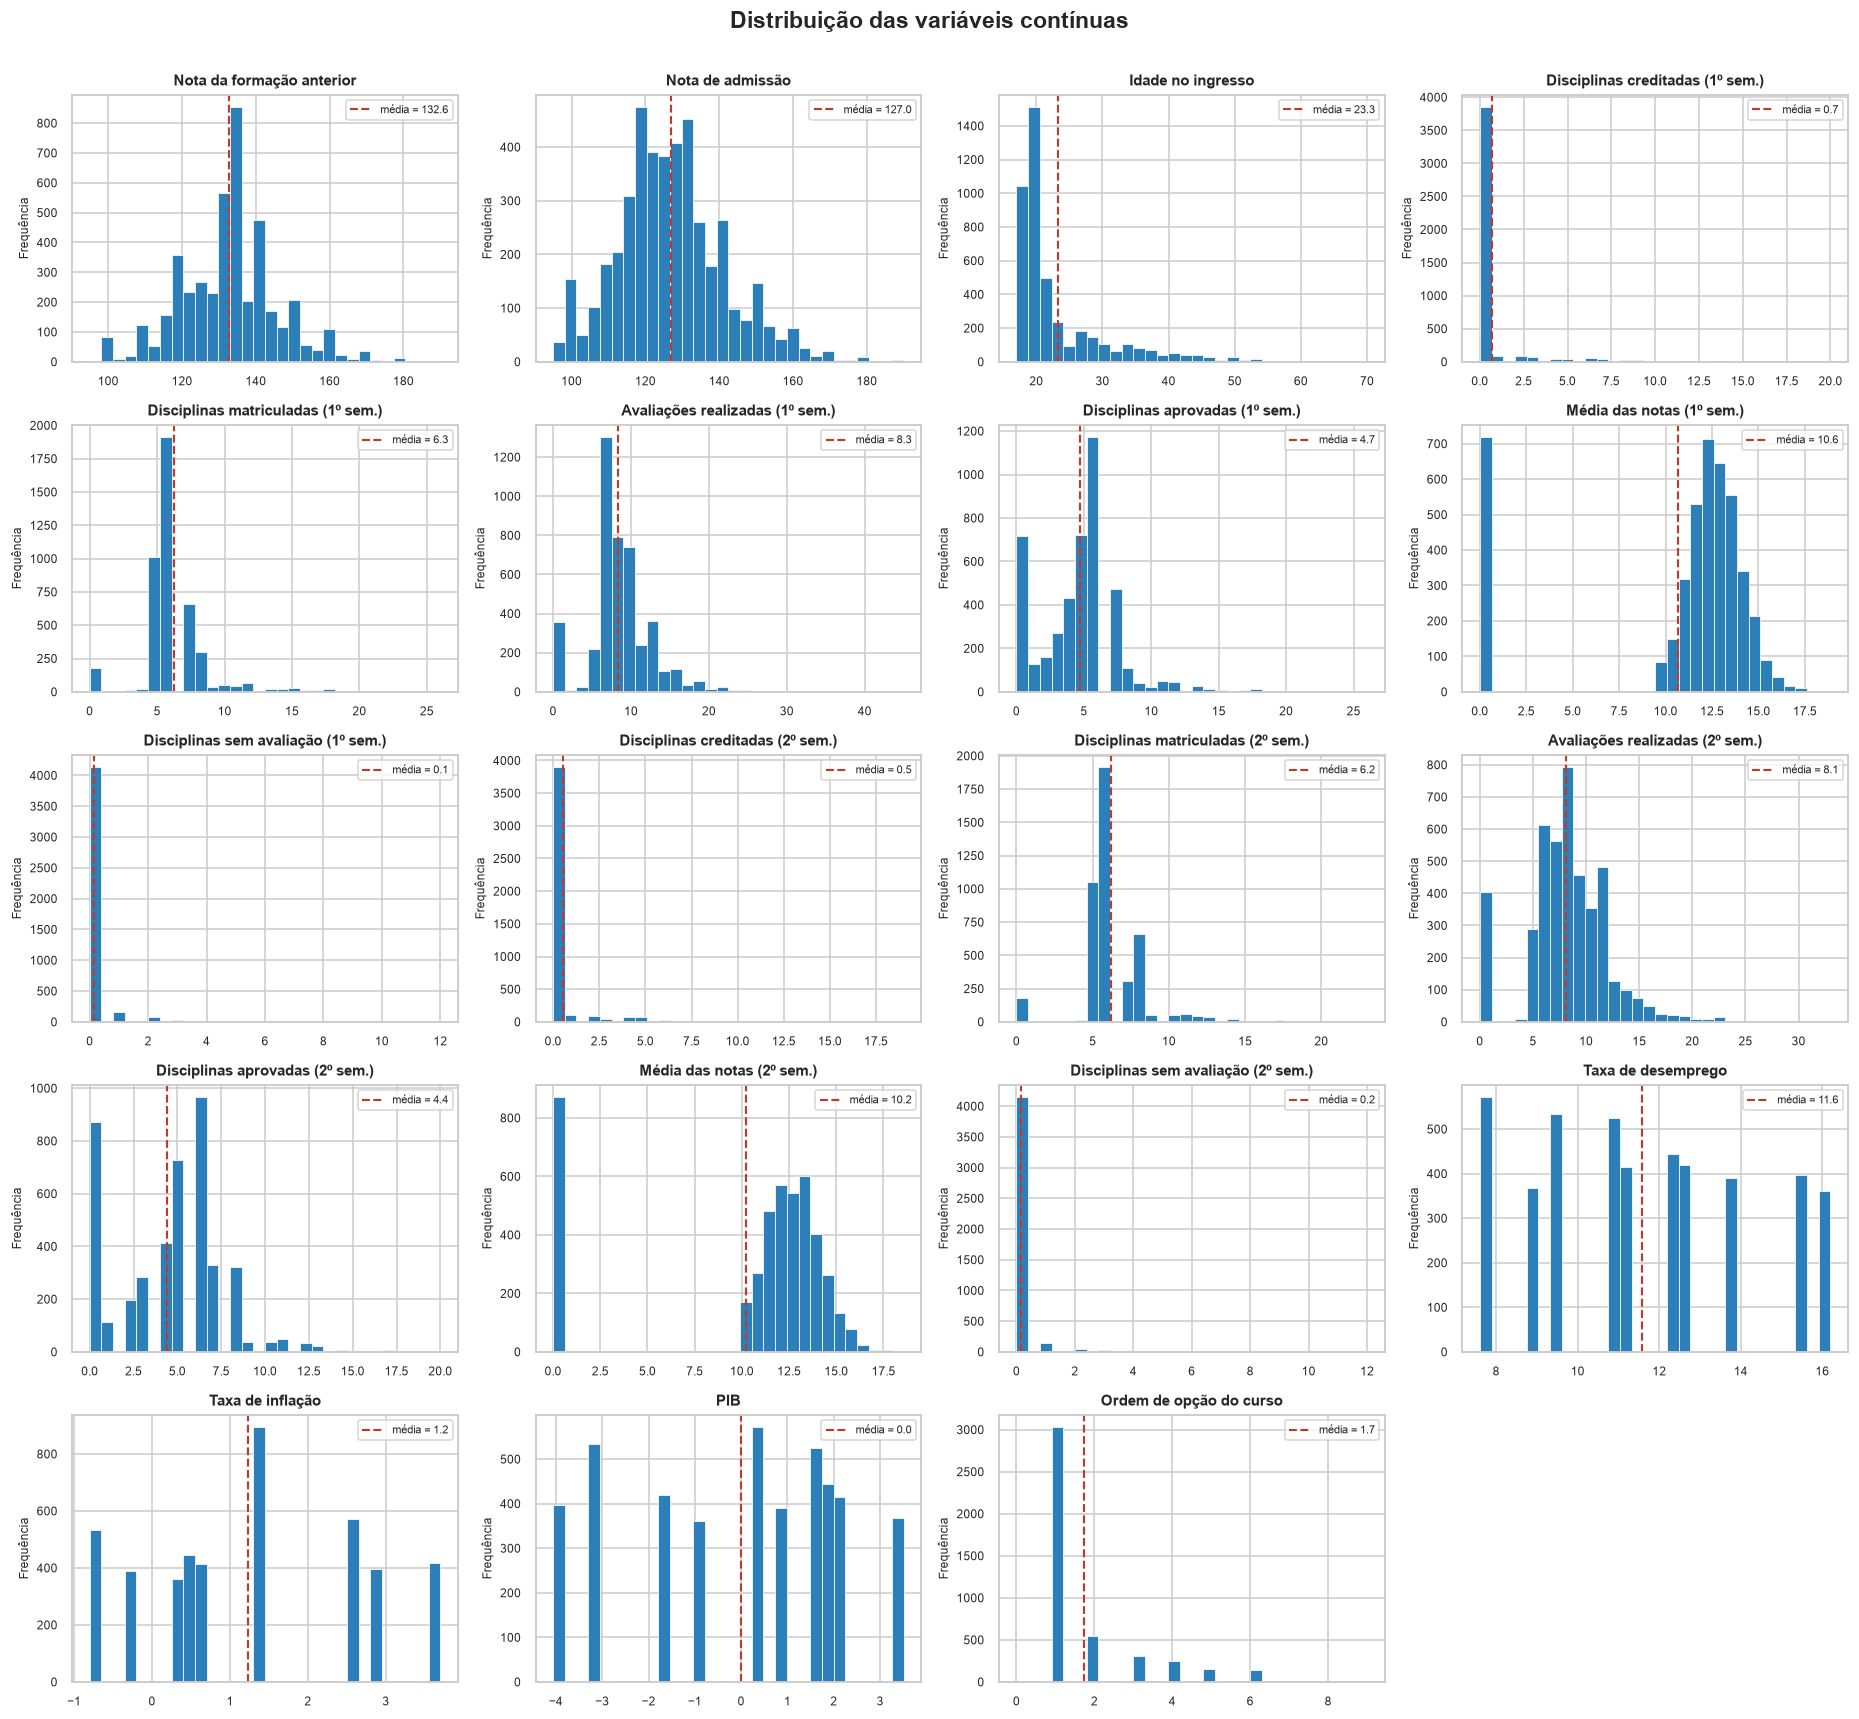

In [14]:
continuas = tipos["continuas"]
n_cols = 4
n_rows = int(np.ceil(len(continuas) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 3.1 * n_rows))
axes = axes.flatten()

for i, col in enumerate(continuas):
    axes[i].hist(df[col], bins=30, color="#2c7fb8", edgecolor="white", linewidth=0.5)
    axes[i].axvline(df[col].mean(), color="#c0392b", linestyle="--", linewidth=1.4,
                    label=f"média = {df[col].mean():.1f}")
    axes[i].set_title(rotulo(col), fontsize=10)
    axes[i].set_ylabel("Frequência", fontsize=8)
    axes[i].tick_params(labelsize=8)
    axes[i].legend(fontsize=7)

for j in range(len(continuas), len(axes)):
    axes[j].axis("off")

plt.suptitle("Distribuição das variáveis contínuas", fontsize=15, fontweight="bold", y=1.005)
plt.tight_layout()
salvar_fig("02_histogramas_continuas.png")
plt.show()

In [15]:
# Assimetria (skewness): |skew| > 1 indica distribuição fortemente assimétrica
assimetria = df[continuas].skew().sort_values(ascending=False)
tab_assim = pd.DataFrame({
    "Variável": [rotulo(i) for i in assimetria.index],
    "Assimetria": assimetria.round(2).values,
    "Interpretação": np.where(assimetria.abs() > 1, "Fortemente assimétrica",
                       np.where(assimetria.abs() > 0.5, "Moderadamente assimétrica", "Aproximadamente simétrica")),
})
display(tab_assim.reset_index(drop=True))

,Variável,Assimetria,Interpretação
0,Disciplinas sem avaliação (1º sem.),8.21,Fortemente assimétrica
1,Disciplinas sem avaliação (2º sem.),7.27,Fortemente assimétrica
2,Disciplinas creditadas (2º sem.),4.63,Fortemente assimétrica
3,Disciplinas creditadas (1º sem.),4.17,Fortemente assimétrica
4,Idade no ingresso,2.05,Fortemente assimétrica
5,Ordem de opção do curso,1.88,Fortemente assimétrica
6,Disciplinas matriculadas (1º sem.),1.62,Fortemente assimétrica
7,Avaliações realizadas (1º sem.),0.98,Moderadamente assimétrica
8,Disciplinas matriculadas (2º sem.),0.79,Moderadamente assimétrica
9,Disciplinas aprovadas (1º sem.),0.77,Moderadamente assimétrica


> ### Conclusão parcial — distribuições
>
> * **Idade no ingresso** é fortemente assimétrica à direita: a maioria ingressa entre 18 e 22 anos,
>   com uma cauda longa de estudantes mais velhos.
> * As variáveis de **disciplinas creditadas** e **sem avaliação** concentram-se quase inteiramente
>   em zero — são eventos raros, com assimetria muito elevada.
> * As **médias semestrais** apresentam um padrão bimodal característico: um pico em zero (alunos sem
>   nenhuma aprovação) e uma distribuição aproximadamente normal em torno de 12–13 (escala portuguesa
>   de 0 a 20). Esse pico em zero é, provavelmente, **o sinal preditivo mais forte do dataset**.
> * **Nota de admissão** e **nota da formação anterior** são razoavelmente simétricas.
>
> **Decisão:** não aplicaremos transformações logarítmicas. Os modelos baseados em árvores
> (Random Forest, XGBoost) são **invariantes a transformações monotônicas**, e a Regressão Logística
> receberá padronização via `StandardScaler`. Transformar as variáveis prejudicaria a
> interpretabilidade dos gráficos SHAP no Notebook 4 — que é o objetivo central deste TCC.

## 8. Análise de correlação

A matriz de correlação de Pearson mostra a associação linear entre pares de variáveis contínuas.
Serve a dois propósitos:

1. Detectar **multicolinearidade** (variáveis quase redundantes), que desestabiliza os coeficientes
   da Regressão Logística;
2. Fornecer uma primeira leitura de **quais atributos se movem junto com a evasão**.

[figura salva] figuras\03_matriz_correlacao.png


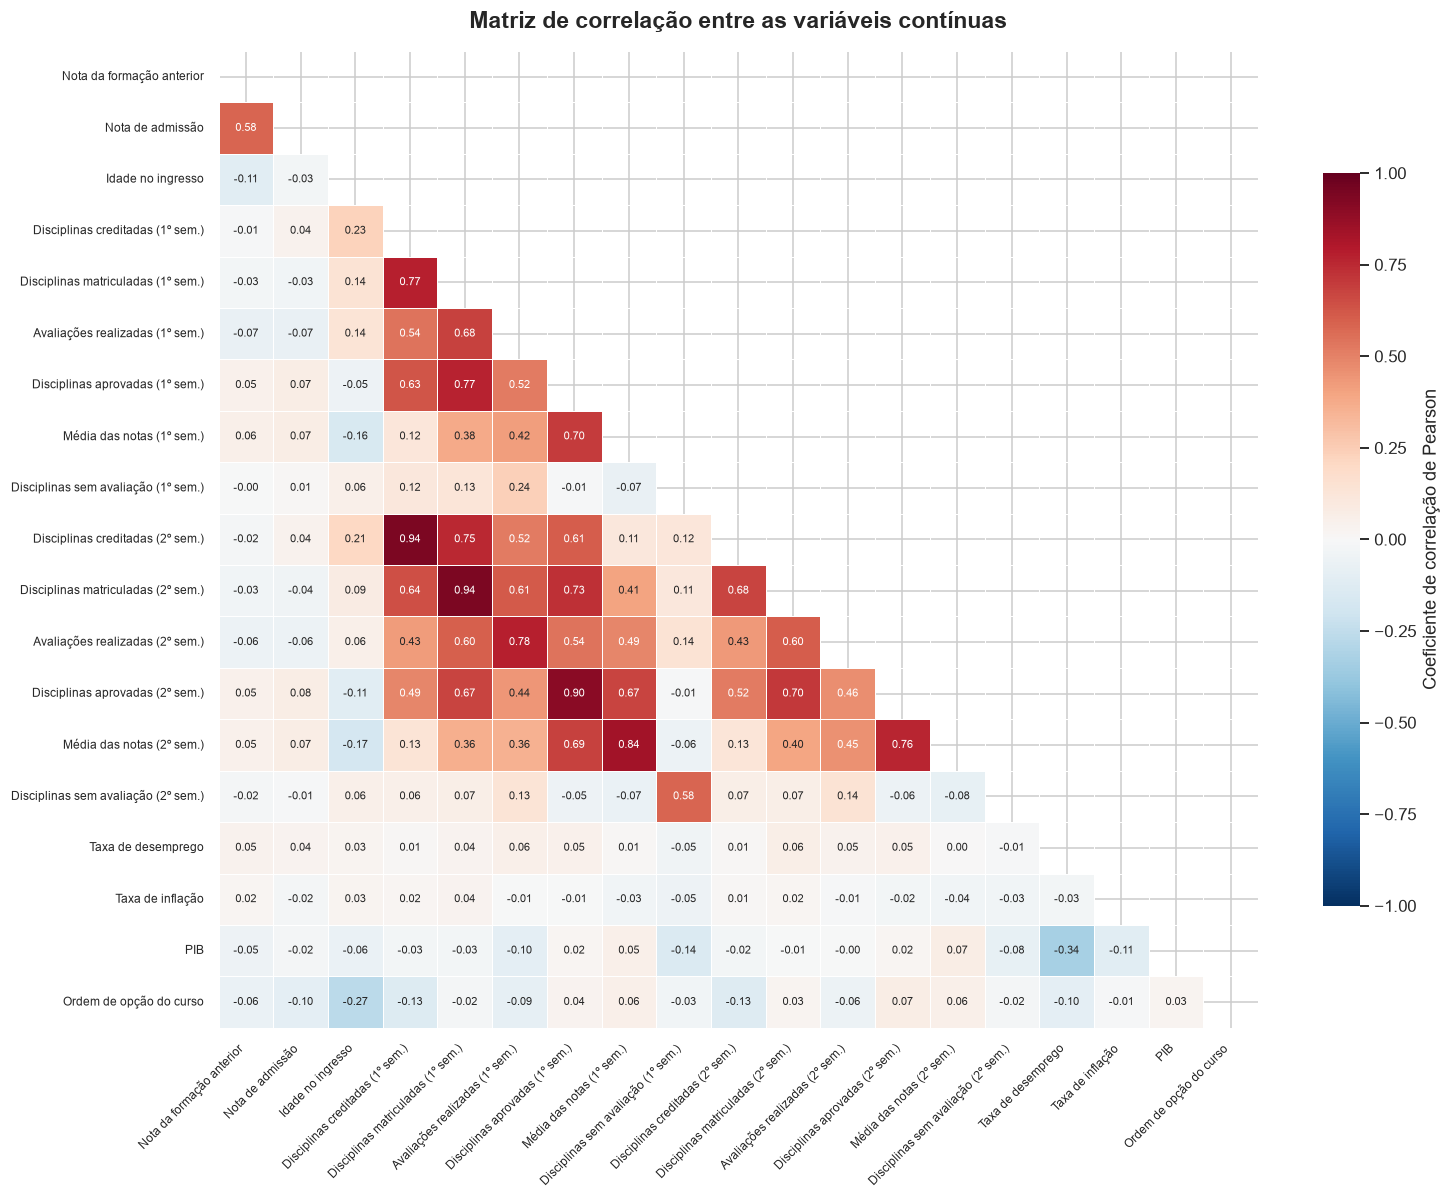

In [16]:
matriz_corr = df[continuas].corr(method="pearson")

plt.figure(figsize=(14, 11))
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))   # oculta o triângulo superior (redundante)
sns.heatmap(matriz_corr, mask=mascara, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.4, linecolor="white",
            cbar_kws={"label": "Coeficiente de correlação de Pearson", "shrink": 0.75},
            xticklabels=[rotulo(c) for c in matriz_corr.columns],
            yticklabels=[rotulo(c) for c in matriz_corr.index])
plt.title("Matriz de correlação entre as variáveis contínuas", fontsize=15, pad=15)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
salvar_fig("03_matriz_correlacao.png")
plt.show()

In [17]:
# Pares com correlação muito alta (|r| >= 0.80) — candidatos a multicolinearidade
pares = (matriz_corr.where(~np.tril(np.ones(matriz_corr.shape)).astype(bool))
         .stack()
         .sort_values(key=abs, ascending=False))
altos = pares[abs(pares) >= 0.80]

print(f"Pares com |r| >= 0,80: {len(altos)}\n")
for (a, b), valor in altos.items():
    print(f"  r = {valor:+.3f}  |  {rotulo(a)}  x  {rotulo(b)}")

Pares com |r| >= 0,80: 4

  r = +0.945  |  Disciplinas creditadas (1º sem.)  x  Disciplinas creditadas (2º sem.)
  r = +0.943  |  Disciplinas matriculadas (1º sem.)  x  Disciplinas matriculadas (2º sem.)
  r = +0.904  |  Disciplinas aprovadas (1º sem.)  x  Disciplinas aprovadas (2º sem.)
  r = +0.837  |  Média das notas (1º sem.)  x  Média das notas (2º sem.)


### 8.1 Correlação com a evasão

Para medir a associação de cada variável com o desfecho, criamos um indicador binário auxiliar
`is_dropout` (1 = evadiu, 0 = demais). A correlação de Pearson entre uma variável contínua e um
indicador binário equivale ao **coeficiente ponto-bisserial**, apropriado para este caso.

Esta variável auxiliar existe **apenas para fins exploratórios** e não integra o conjunto de treino.

In [18]:
df_corr = df.copy()
df_corr["is_dropout"] = (df_corr["target"] == "Dropout").astype(int)

# Consideramos contínuas + binárias (para binárias, Pearson equivale ao coeficiente phi)
candidatas = tipos["continuas"] + tipos["binarias"]
corr_alvo = df_corr[candidatas + ["is_dropout"]].corr()["is_dropout"].drop("is_dropout")
top10 = corr_alvo.reindex(corr_alvo.abs().sort_values(ascending=False).index).head(10)

tabela_top10 = pd.DataFrame({
    "Variável": [rotulo(i) for i in top10.index],
    "Correlação com evasão": top10.round(3).values,
    "Direção": np.where(top10 > 0, "↑ valor  →  ↑ risco de evasão",
                                    "↑ valor  →  ↓ risco de evasão"),
})
print("TOP 10 VARIÁVEIS MAIS CORRELACIONADAS COM A EVASÃO\n")
display(tabela_top10.reset_index(drop=True))

TOP 10 VARIÁVEIS MAIS CORRELACIONADAS COM A EVASÃO



,Variável,Correlação com evasão,Direção
0,Média das notas (2º sem.),-0.572,↑ valor → ↓ risco de evasão
1,Disciplinas aprovadas (2º sem.),-0.570,↑ valor → ↓ risco de evasão
2,Média das notas (1º sem.),-0.481,↑ valor → ↓ risco de evasão
3,Disciplinas aprovadas (1º sem.),-0.479,↑ valor → ↓ risco de evasão
4,Mensalidades em dia,-0.429,↑ valor → ↓ risco de evasão
5,Idade no ingresso,0.254,↑ valor → ↑ risco de evasão
6,Bolsista,-0.245,↑ valor → ↓ risco de evasão
7,Inadimplente,0.229,↑ valor → ↑ risco de evasão
8,Gênero,0.204,↑ valor → ↑ risco de evasão
9,Avaliações realizadas (2º sem.),-0.155,↑ valor → ↓ risco de evasão


[figura salva] figuras\04_top10_correlacao_evasao.png


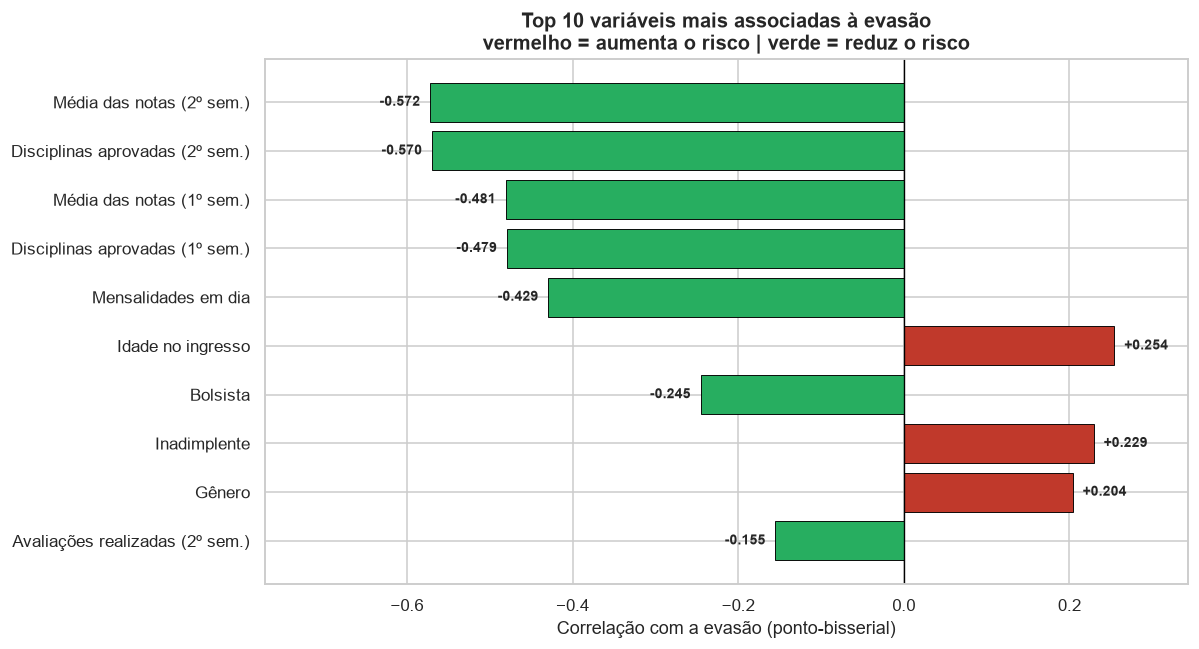

In [19]:
plt.figure(figsize=(11, 6))
cores = ["#c0392b" if v > 0 else "#27ae60" for v in top10.values]
plt.barh([rotulo(i) for i in top10.index], top10.values, color=cores,
         edgecolor="black", linewidth=0.6)
plt.axvline(0, color="black", linewidth=0.9)
for i, v in enumerate(top10.values):
    plt.text(v + (0.012 if v > 0 else -0.012), i, f"{v:+.3f}",
             va="center", ha="left" if v > 0 else "right", fontsize=9, fontweight="bold")
plt.gca().invert_yaxis()
plt.xlabel("Correlação com a evasão (ponto-bisserial)")
plt.title("Top 10 variáveis mais associadas à evasão\n"
          "vermelho = aumenta o risco | verde = reduz o risco", fontsize=13)
plt.xlim(min(top10.min() * 1.35, -0.1), max(top10.max() * 1.35, 0.1))
plt.tight_layout()
salvar_fig("04_top10_correlacao_evasao.png")
plt.show()

> ### Conclusão parcial — correlações
>
> **Multicolinearidade.** Há pares fortemente correlacionados, todos com explicação estrutural clara:
> as métricas do 1º e do 2º semestre medem a mesma dimensão em momentos diferentes, e
> `disciplinas matriculadas` × `disciplinas avaliadas` são quase a mesma informação por construção.
> Isso **penaliza a estabilidade dos coeficientes da Regressão Logística**, mas praticamente não
> afeta Random Forest e XGBoost. Como o objetivo do TCC é interpretabilidade via SHAP — e não
> inferência sobre coeficientes isolados —, **optamos por manter todas as variáveis**, em linha com a
> restrição metodológica de não realizar seleção agressiva de atributos sem justificativa.
>
> **Associação com a evasão.** O ranking é dominado pelo **desempenho acadêmico do primeiro ano**:
> o número de **disciplinas aprovadas** e a **média das notas** nos dois semestres apresentam
> correlação negativa forte com a evasão — quanto melhor o desempenho, menor o risco. Em seguida
> aparecem fatores **financeiros** (mensalidades em dia, bolsa de estudos, inadimplência) e a
> **idade no ingresso** (positiva: alunos mais velhos evadem mais).
>
> Esse padrão **confirma a literatura** (Tinto, 1975; Realinho et al., 2022): a evasão é um processo
> majoritariamente ligado à integração acadêmica e à condição financeira, e **manifesta-se já no
> primeiro ano** — o que sustenta a viabilidade prática de um sistema de alerta precoce.

## 9. Comportamento das variáveis por classe

Os boxplots abaixo comparam a distribuição das variáveis mais relevantes **entre as três situações**.
É a evidência visual de que essas variáveis realmente **separam** os grupos — e não apenas
apresentam correlação numérica.

[figura salva] figuras\05_boxplots_por_classe.png


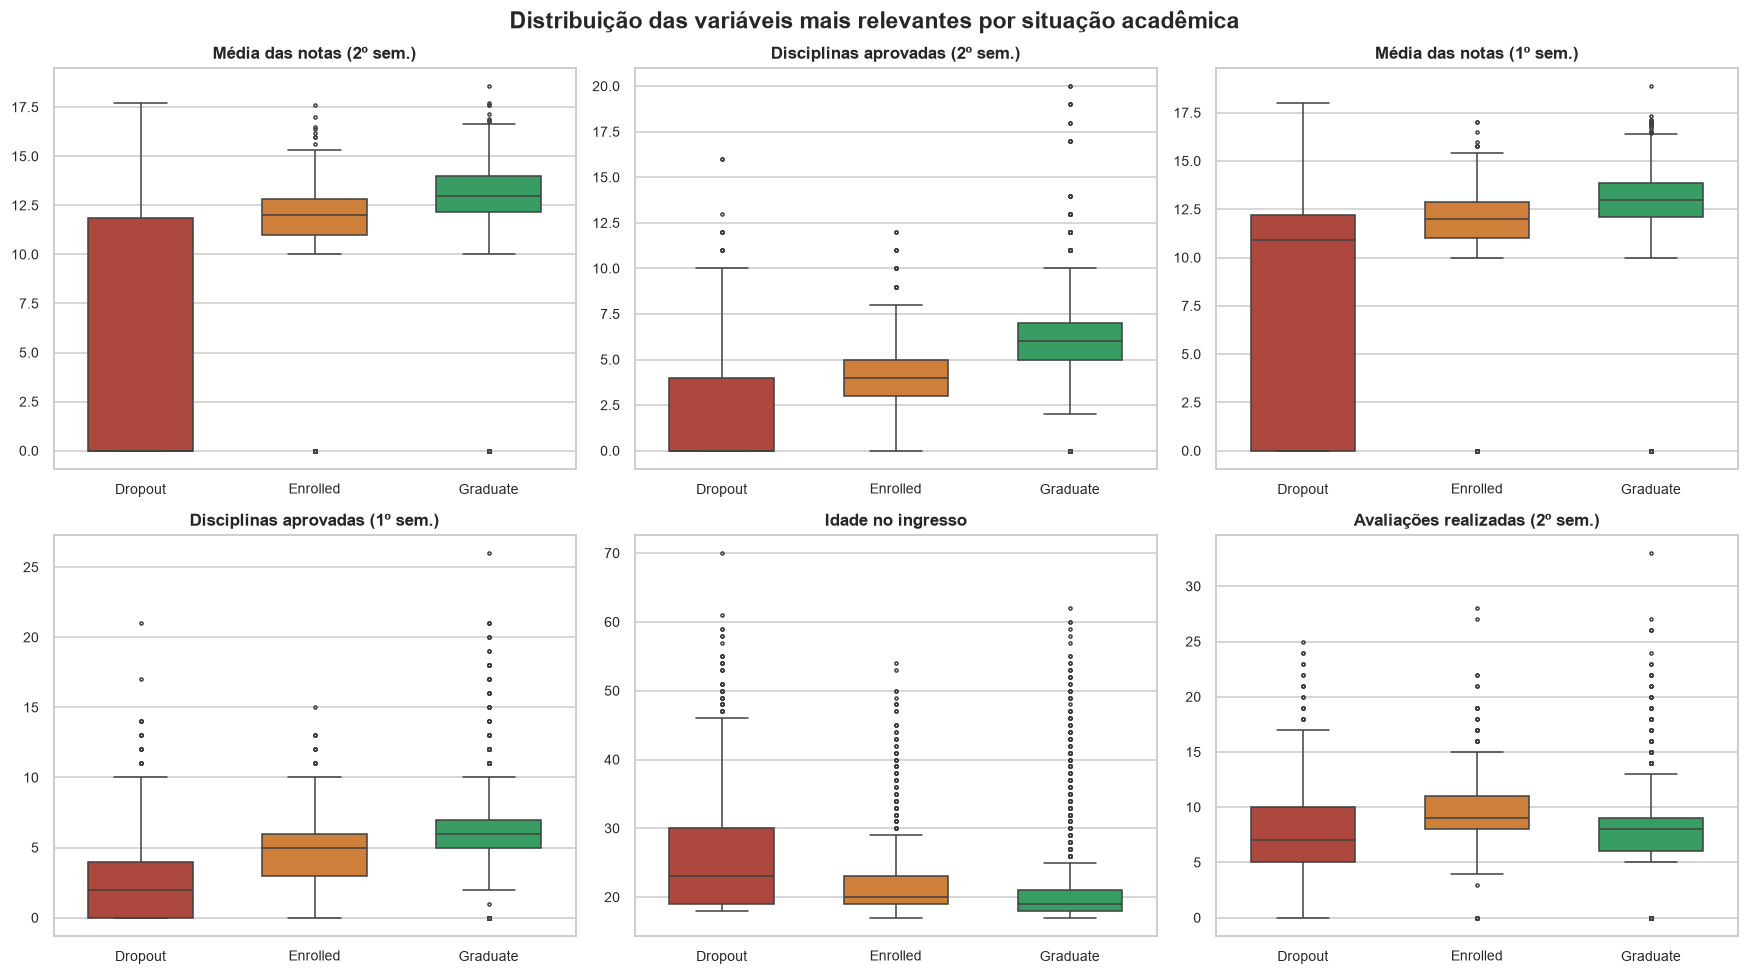

In [20]:
# Seleciona as variáveis contínuas mais correlacionadas com a evasão
vars_boxplot = [v for v in top10.index if v in tipos["continuas"]][:6]
if len(vars_boxplot) < 6:                       # completa com as demais, se necessário
    extras = [v for v in corr_alvo.abs().sort_values(ascending=False).index
              if v in tipos["continuas"] and v not in vars_boxplot]
    vars_boxplot += extras[: 6 - len(vars_boxplot)]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(vars_boxplot):
    sns.boxplot(data=df, x="target", y=col, order=ordem, ax=axes[i],
                hue="target", hue_order=ordem, palette=CORES_CLASSE,
                legend=False, width=0.6, fliersize=2)
    axes[i].set_title(rotulo(col), fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].tick_params(labelsize=9)

plt.suptitle("Distribuição das variáveis mais relevantes por situação acadêmica",
             fontsize=15, fontweight="bold")
plt.tight_layout()
salvar_fig("05_boxplots_por_classe.png")
plt.show()

In [21]:
# Tabela de medianas por classe — leitura numérica do que os boxplots mostram
resumo_classe = df.groupby("target")[vars_boxplot].median().T
resumo_classe.index = [rotulo(i) for i in resumo_classe.index]
resumo_classe = resumo_classe[[c for c in ordem if c in resumo_classe.columns]]
print("Mediana de cada variável, por situação acadêmica:\n")
display(resumo_classe.round(2))

Mediana de cada variável, por situação acadêmica:



target,Dropout,Enrolled,Graduate
Média das notas (2º sem.),0.00,12.0,13.0
Disciplinas aprovadas (2º sem.),0.00,4.0,6.0
Média das notas (1º sem.),10.93,12.0,13.0
Disciplinas aprovadas (1º sem.),2.00,5.0,6.0
Idade no ingresso,23.00,20.0,19.0
Avaliações realizadas (2º sem.),7.00,9.0,8.0


> ### Conclusão parcial — separabilidade
>
> Os boxplots mostram uma separação **visualmente inequívoca**: a mediana de disciplinas aprovadas no
> 2º semestre é praticamente **zero para quem evade** e situa-se em torno de **5 a 6 para quem se
> forma**. O mesmo padrão se repete na média das notas.
>
> Note que a classe `Enrolled` ocupa consistentemente uma **posição intermediária** entre `Dropout` e
> `Graduate`. Essa é a evidência empírica que justifica removê-la: ela não é uma categoria com
> identidade própria, e sim uma **mistura de casos ainda indefinidos** — mantê-la forçaria o
> classificador a aprender uma fronteira que não existe no fenômeno estudado.

## 10. Análise de outliers (método IQR)

Usamos o critério de Tukey: um valor é considerado atípico quando está fora do intervalo
`[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]`, onde `IQR = Q3 − Q1`.

**Importante:** identificar outliers **não implica removê-los**. Em predição de evasão, os valores
extremos são justamente os casos de maior interesse — um aluno de 60 anos com zero aprovações é
exatamente o perfil que o modelo precisa reconhecer.

In [22]:
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mascara = (serie < lim_inf) | (serie > lim_sup)
    return mascara.sum(), lim_inf, lim_sup


linhas = []
for col in continuas:
    n_out, li, ls = contar_outliers_iqr(df[col])
    linhas.append({
        "Variável": rotulo(col),
        "Limite inferior": round(li, 2),
        "Limite superior": round(ls, 2),
        "Nº de outliers": int(n_out),
        "% do total": round(n_out / len(df) * 100, 2),
    })

tab_outliers = pd.DataFrame(linhas).sort_values("Nº de outliers", ascending=False)
display(tab_outliers.reset_index(drop=True))

total_linhas_com_outlier = df[continuas].apply(
    lambda s: (s < s.quantile(0.25) - 1.5 * (s.quantile(0.75) - s.quantile(0.25))) |
              (s > s.quantile(0.75) + 1.5 * (s.quantile(0.75) - s.quantile(0.25)))
).any(axis=1).sum()
print(f"\nRegistros com ao menos um outlier: {total_linhas_com_outlier} "
      f"({total_linhas_com_outlier / len(df) * 100:.1f}% da amostra)")

,Variável,Limite inferior,Limite superior,Nº de outliers,% do total
0,Média das notas (2º sem.),6.88,17.21,877,19.82
1,Média das notas (1º sem.),7.40,17.00,726,16.41
2,Disciplinas creditadas (1º sem.),0.00,0.00,577,13.04
3,Ordem de opção do curso,-0.50,3.50,541,12.23
4,Disciplinas creditadas (2º sem.),0.00,0.00,530,11.98
5,Idade no ingresso,10.00,34.00,441,9.97
6,Disciplinas matriculadas (1º sem.),2.00,10.00,424,9.58
7,Disciplinas matriculadas (2º sem.),2.00,10.00,369,8.34
8,Disciplinas sem avaliação (1º sem.),0.00,0.00,294,6.65
9,Disciplinas sem avaliação (2º sem.),0.00,0.00,282,6.37



Registros com ao menos um outlier: 2422 (54.7% da amostra)


In [23]:
# Onde estão os outliers? Comparação da taxa de evasão entre registros atípicos e normais
mascara_outlier = df[continuas].apply(
    lambda s: (s < s.quantile(0.25) - 1.5 * (s.quantile(0.75) - s.quantile(0.25))) |
              (s > s.quantile(0.75) + 1.5 * (s.quantile(0.75) - s.quantile(0.25)))
).any(axis=1)

taxa_out = (df.loc[mascara_outlier, "target"] == "Dropout").mean() * 100
taxa_normal = (df.loc[~mascara_outlier, "target"] == "Dropout").mean() * 100

print(f"Taxa de evasão entre registros COM outlier : {taxa_out:.1f}%")
print(f"Taxa de evasão entre registros SEM outlier : {taxa_normal:.1f}%")
print(f"Diferença                                  : {taxa_out - taxa_normal:+.1f} pontos percentuais")

Taxa de evasão entre registros COM outlier : 45.7%
Taxa de evasão entre registros SEM outlier : 15.6%
Diferença                                  : +30.1 pontos percentuais


> ### Conclusão parcial — outliers
>
> Uma parcela expressiva da amostra apresenta pelo menos um valor atípico, concentrados sobretudo em
> `disciplinas creditadas`, `disciplinas sem avaliação` e `idade no ingresso`.
>
> **Decisão metodológica: os outliers serão mantidos.** Três razões sustentam essa escolha:
>
> 1. Eles **não são erros de medição** — são registros legítimos de trajetórias acadêmicas atípicas;
> 2. A comparação acima mostra que registros com valores extremos apresentam taxa de evasão
>    **distinta** da dos demais: descartá-los eliminaria justamente o sinal que buscamos capturar;
> 3. Random Forest e XGBoost, os modelos centrais deste trabalho, são **robustos a valores extremos**
>    por operarem com partições ordinais, e não com distâncias.
>
> Remover esses casos configuraria uma forma sutil de *survivorship bias*, inflando artificialmente
> as métricas e produzindo um modelo inútil na prática — pois ele deixaria de reconhecer exatamente
> os alunos em situação mais crítica.

## 11. Persistência do conjunto tratado

Salvamos o dataset com os nomes de coluna já padronizados, **sem nenhuma transformação estatística**.
Toda codificação, escalonamento e balanceamento pertencem à Fase 3 do CRISP-DM (Notebook 2) e devem
ocorrer **após** a divisão treino/teste, para evitar vazamento de informação.

In [24]:
caminho_csv = os.path.join(DIR_DADOS, "dataset_limpo.csv")
df.to_csv(caminho_csv, index=False, encoding="utf-8")

print(f"[OK] Dataset salvo em: {caminho_csv}")
print(f"     Dimensões: {df.shape[0]} x {df.shape[1]}")
print(f"     Origem   : {origem}")

# Verificação de integridade da escrita
df_check = pd.read_csv(caminho_csv)
assert df_check.shape == df.shape, "Divergência de dimensões após salvar!"
assert list(df_check.columns) == list(df.columns), "Divergência de colunas após salvar!"
print("[OK] Releitura verificada — arquivo íntegro.")

[OK] Dataset salvo em: dados\dataset_limpo.csv
     Dimensões: 4424 x 37
     Origem   : MySQL
[OK] Releitura verificada — arquivo íntegro.


---

## 12. Síntese da Fase 2 do CRISP-DM

### O que foi estabelecido

| Achado | Evidência | Consequência para o pipeline |
|---|---|---|
| Dados completos e sem duplicatas | 0 nulos, 0 duplicados | Dispensa imputação; elimina uma fonte de viés |
| Desbalanceamento moderado (≈ 2,8 : 1) | Graduate 50% / Dropout 32% / Enrolled 18% | Justifica SMOTE **só no treino**; acurácia descartada como métrica principal |
| `Enrolled` é uma classe ambígua | Ocupa posição intermediária em todos os boxplots | Sustenta a formulação binária (Notebook 2) |
| Muitos "numéricos" são códigos categóricos | `course`, `application_mode`, ocupação dos pais | Exige codificação adequada, não escalonamento |
| Desempenho do 1º ano domina a associação com evasão | Aprovações e médias lideram o ranking de correlação | Confirma viabilidade de alerta precoce |
| Fatores financeiros são relevantes | Mensalidades em dia, bolsa, inadimplência no top 10 | Aponta intervenção institucional acionável |
| Multicolinearidade entre semestres | \|r\| ≥ 0,80 em vários pares | Aceitável para modelos de árvore; registrada como limitação da Regressão Logística |
| Outliers são informativos | Taxa de evasão diferente entre atípicos e normais | Serão mantidos |

### Respondendo à pergunta de pesquisa

A análise exploratória indica que **existe sinal suficiente nos dados para construir um preditor de
evasão**: as variáveis de desempenho acadêmico do primeiro ano separam visualmente os grupos, e os
fatores socioeconômicos acrescentam informação complementar. Isso sustenta a hipótese central do
trabalho — a de que é possível identificar alunos em risco **antes da desistência efetiva**.

### Limitações já identificáveis nesta fase

* Os dados provêm de **uma única instituição portuguesa** (Instituto Politécnico de Portalegre);
  diferenças de sistema educacional, escala de notas (0–20) e política de bolsas limitam a
  generalização direta para o contexto brasileiro.
* O dataset é **transversal**, não longitudinal: registra o estado ao fim do período de observação,
  sem a sequência temporal completa da trajetória do aluno.
* Não há variáveis de **integração social** (participação em atividades, vínculo com colegas),
  dimensão central no modelo teórico de Tinto (1975).

### Próximo passo

**Notebook 2 — Pré-processamento (Fase 3 do CRISP-DM):** definição da formulação do problema
(binária × multiclasse), codificação das categóricas, padronização, divisão estratificada 80/20 e
aplicação de SMOTE exclusivamente sobre o conjunto de treino.